In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def algorithm(e, lambda_val, alpha, delta, random_uniform, K, M, verbose=False):
    # Constants
    S, A = 2, 2  # States, Actions
    DC, CC, DD, CD = 1, 0.8, 0.2, 0  # Payoffs for the Prisoner's Dilemma

    # Reward matrix for Player 1 against Player 2's actions
    r1 = np.array([[CC, CD], [DC, DD]])

    # State transitions
    P_CC = np.array([[1, 0], [1, 0]])  # Transition when both cooperate
    P_CD = np.array([[0, 1], [0, 1]])  # Transition when one cooperates, the other defects
    P_DC = P_CD
    P_DD = P_CD

    def player2_gt_strategy(triggered_defection):
        """Player 2 plays Grim Trigger: cooperate unless defected upon."""
        return np.array([0, 1]) if triggered_defection else np.array([1, 0])

    # Initialize Q-values and action tracking
    q1_history = []
    cooperation_count = 0
    defection_count = 0
    
    for m in range(M):
        # Initialize Q-values
        if random_uniform:
            q1 = np.random.rand(A, S)
            #q1 = np.ones((A, S)) * 0.5  # Initialize with equal values for both actions

        else:
            temp1, temp2, temp3, temp4 = np.random.rand(), np.random.rand(), np.random.rand(), np.random.rand()
            q1 = np.array([[temp2 + temp1, temp3], [temp1, temp4 + temp3]])

        q1_val = q1.copy()
        error = 1  # Start with error as true
        triggered_defection = False  # Reset Grim Trigger flag for each sample

        while error:
            # Set Player 2's strategy based on Grim Trigger
            pi2 = np.array([player2_gt_strategy(triggered_defection), player2_gt_strategy(triggered_defection)]).T
            r1_pi2 = np.dot(r1, pi2)

            # Transition probabilities for Player 1 given Player 2's strategy
            P1_C_pi2 = np.array([P_CC[0] * pi2[0, 0] + P_CD[0] * pi2[1, 0], P_CC[1] * pi2[0, 1] + P_CD[1] * pi2[1, 1]])
            P1_D_pi2 = np.array([P_DC[0] * pi2[0, 0] + P_DD[0] * pi2[1, 0], P_DC[1] * pi2[0, 1] + P_DD[1] * pi2[1, 1]])

            # Q-value update iterations
            for k in range(K):
                q1_max = (1 - e) * np.max(q1_val, axis=0) + e * np.mean(q1_val, axis=0)
                q1_new = np.vstack((np.dot(P1_C_pi2, q1_max), np.dot(P1_D_pi2, q1_max)))
                q1_new = r1_pi2 + delta * q1_new
                q1_val = q1_new.copy()
                
                

            # Check for convergence
            error = np.any(np.abs(q1_val - q1) > 1e-3)

            # Update Player 1's Q-values with learning rate, probabilistically based on lambda_val
            q1 += (np.random.rand() > lambda_val) * alpha * (q1_val - q1)
            q1_history.append(q1.copy())

            # Determine if Player 1 chooses to defect
            action_chosen = np.argmax(q1, axis=0)  # Best action per state (0 for cooperate, 1 for defect)
            if action_chosen[0] == 1 or action_chosen[1] == 1:
                defection_count += 1
                triggered_defection = True  # Activate Grim Trigger
            else:
                cooperation_count += 1

            # Copy updated Q-values for the next iteration of the convergence check
            q1_val = q1.copy()

    if verbose:
        print("Final Q-values for Player 1:")
        print(q1)
        print(f"Cooperation Count: {cooperation_count}, Defection Count: {defection_count}")

    return q1, q1_history, cooperation_count, defection_count


In [5]:
def algorithm_print(e, lambda_val, alpha, delta, random_uniform, K, M, verbose=False):
    # Constants
    S, A = 2, 2  # States, Actions
    DC, CC, DD, CD = 1, 0.8, 0.2, 0  # Payoffs for the Prisoner's Dilemma

    # Reward matrix for Player 1 against Player 2's actions
    r1 = np.array([[CC, CD], [DC, DD]])

    # State transitions
    P_CC = np.array([[1, 0], [1, 0]])  # Transition when both cooperate
    P_CD = np.array([[0, 1], [0, 1]])  # Transition when one cooperates, the other defects
    P_DC = P_CD
    P_DD = P_CD

    def player2_gt_strategy(triggered_defection):
        """Player 2 plays Grim Trigger: cooperate unless defected upon."""
        if triggered_defection:
            return np.array([0, 1])  # Full defection (plays "D" with prob 1)
        else:
            return np.array([1, 0])  # Full cooperation (plays "C" with prob 1)

    # Initialize Q-values for Player 1
    q1_history = []  # To track Q-values over time
    actions_taken = []  # To track actions taken by Player 1
    cooperations = 0  # Count the number of cooperations (action 0)
    defections = 0  # Count the number of defections (action 1)
    previous_opponent_move = 0
    for m in range(M):
        # Initialize Q-values
        if random_uniform: 
            q1 = np.random.rand(A, S)  # Random initialization
        else:
            q1 = np.ones((A, S)) * 0.5  # Equal initialization for both actions

        q1_val = q1.copy()
        error = 1
        count = 0
        triggered_defection = False  # Reset Grim Trigger flag for each sample

        while error:
            # Set Player 2's strategy using GT, considering if defection was triggered
            pi2 = np.array([player2_gt_strategy(triggered_defection), player2_gt_strategy(triggered_defection)]).T

            # Payoff vector for Player 1 given Player 2's GT policy
            r1_pi2 = np.dot(r1, pi2)

            # Transition probabilities for Player 1 given Player 2's GT policy
            P1_C_pi2 = np.array([P_CC[0] * pi2[0, 0] + P_CD[0] * pi2[1, 0], P_CC[1] * pi2[0, 1] + P_CD[1] * pi2[1, 1]])
            P1_D_pi2 = np.array([P_DC[0] * pi2[0, 0] + P_DD[0] * pi2[1, 0], P_DC[1] * pi2[0, 1] + P_DD[1] * pi2[1, 1]])

            for k in range(K):
                # Update Player 1's Q-values based on Player 2's fixed GT strategy
                q1_max = (1 - e) * np.max(q1_val, axis=0) + e * np.mean(q1_val, axis=0)
                q1_new = np.vstack((np.dot(P1_C_pi2, q1_max), np.dot(P1_D_pi2, q1_max)))
                q1_new = r1_pi2 + delta * q1_new
                q1_val = q1_new.copy()

            # Check for convergence in Q-values
            error = np.any(np.abs(q1_val - q1) > 1e-3)

            # Update Player 1's Q-values with learning rate
            q1 += (np.random.rand() > lambda_val) * alpha * (q1_val - q1)

            # Store Q-values over time for plotting
            q1_history.append(q1.copy())

            # Track the action taken by Player 1 (Cooperate = 0, Defect = 1)
            action = np.argmax(q1[:, 0])  # Action in state 0
            actions_taken.append(action)  # Store action taken in each iteration

            # Update collaboration/defection counters
            if action == 0:
                cooperations += 1
            else:
                defections += 1

            # Check if Player 1 has chosen to defect (action 1)
            if np.argmax(q1[:, 0]) == 1 or np.argmax(q1[:, 1]) == 1:
                triggered_defection = True  # Activate Grim Trigger

            # Copy updated Q-values
            q1_val = q1.copy()
            count += 1

    if verbose:
        print("Final Q-values for Player 1:")
        print(q1)

    # Print final statistics on collaboration and defection
    print(f"Number of collaborations (Cooperation, Action 0): {cooperations}")
    print(f"Number of defections (Defection, Action 1): {defections}")

    # Check if delta > 0.9, player should cooperate more, if delta < 0.9, player should defect more
    if delta > 0.9:
        print("With delta > 0.9, the player is expected to collaborate more.")
    else:
        print("With delta < 0.9, the player is expected to defect more.")

    # Convert q1_history to a numpy array for indexing
    q1_history = np.array(q1_history)

    # Create subplots for each state-action pair
    fig, axs = plt.subplots(2, 2, figsize=(8, 8))

    # State 0, Action 0 (Cooperate, State 0)
    axs[0, 0].plot(q1_history[:, 0, 0], label="Q-value for Action 0 (Cooperate, State 0)", linestyle='--')
    axs[0, 0].set_title("State 0, Action 0: Q-values over Time")
    axs[0, 0].set_xlabel("Iteration")
    axs[0, 0].set_ylabel("Q-value")
    axs[0, 0].legend()

    # State 0, Action 1 (Defect, State 0)
    axs[0, 1].plot(q1_history[:, 1, 0], label="Q-value for Action 1 (Defect, State 0)", linestyle='-.')
    axs[0, 1].set_title("State 0, Action 1: Q-values over Time")
    axs[0, 1].set_xlabel("Iteration")
    axs[0, 1].set_ylabel("Q-value")
    axs[0, 1].legend()

    # State 1, Action 0 (Cooperate, State 1)
    axs[1, 0].plot(q1_history[:, 0, 1], label="Q-value for Action 0 (Cooperate, State 1)", linestyle='--')
    axs[1, 0].set_title("State 1, Action 0: Q-values over Time")
    axs[1, 0].set_xlabel("Iteration")
    axs[1, 0].set_ylabel("Q-value")
    axs[1, 0].legend()

    # State 1, Action 1 (Defect, State 1)
    axs[1, 1].plot(q1_history[:, 1, 1], label="Q-value for Action 1 (Defect, State 1)", linestyle='-.')
    axs[1, 1].set_title("State 1, Action 1: Q-values over Time")
    axs[1, 1].set_xlabel("Iteration")
    axs[1, 1].set_ylabel("Q-value")
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()

    return q1, q1_history


Final Q-values for Player 1:
[[1.70991178 1.70925983]
 [1.90908213 1.90984588]]
Number of collaborations (Cooperation, Action 0): 393
Number of defections (Defection, Action 1): 7123
With delta < 0.9, the player is expected to defect more.


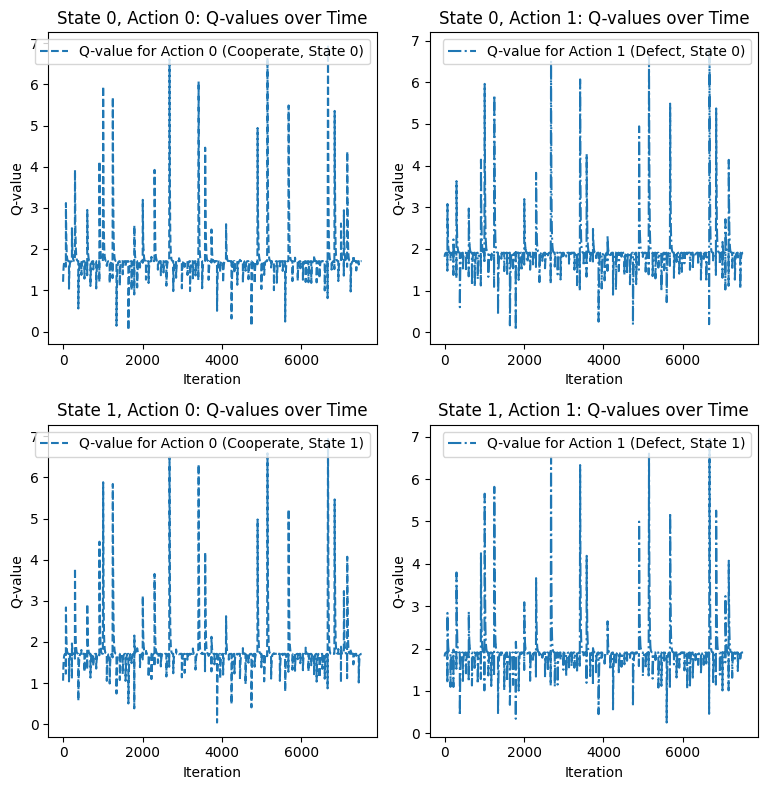

(array([[1.70991178, 1.70925983],
        [1.90908213, 1.90984588]]),
 array([[[1.20805043, 1.05610002],
         [1.80957893, 1.81432216]],
 
        [[1.25824539, 1.12149002],
         [1.81962103, 1.82388994]],
 
        [[1.25824539, 1.12149002],
         [1.81962103, 1.82388994]],
 
        ...,
 
        [[1.70990198, 1.70917759],
         [1.90898015, 1.90982876]],
 
        [[1.70991178, 1.70925983],
         [1.90908213, 1.90984588]],
 
        [[1.70991178, 1.70925983],
         [1.90908213, 1.90984588]]]))

In [6]:
algorithm_print(e=0.1, lambda_val=0.1, alpha=0.1, delta=0.9, random_uniform=True, K=500, M=100, verbose=True)

In [11]:
algorithm_print(e=0.1, lambda_val=0.1, alpha=0.1, delta=0.9, random_uniform=True, K=50, M=100, verbose=True)

NameError: name 'algorithm_print' is not defined

In [8]:
def algorithm_edecay(e_initial, lambda_val, alpha, delta, random_uniform, K, M, e_decay,  error_stop = 'any', verbose=False):
    # Constants
    S, A = 2, 2  # States, Actions
    DC, CC, DD, CD = 1, 0.8, 0.2, 0  # Payoffs for the Prisoner's Dilemma

    # Reward matrix for Player 1 against Player 2's actions
    r1 = np.array([[CC, CD], [DC, DD]])

    # State transitions
    P_CC = np.array([[1, 0], [1, 0]])  # Transition when both cooperate
    P_CD = np.array([[0, 1], [0, 1]])  # Transition when one cooperates, the other defects
    P_DC = P_CD
    P_DD = P_CD

    def player2_gt_strategy(triggered_defection):
        """Player 2 plays Grim Trigger: cooperate unless defected upon."""
        if triggered_defection:
            return np.array([0, 1])  # Full defection (plays "D" with prob 1)
        else:
            return np.array([1, 0])  # Full cooperation (plays "C" with prob 1)
    def player2_tit_for_tat(previous_opponent_move):
        """Player 2 plays Tit-for-Tat: cooperate on the first round, 
        then replicate opponent's previous move."""
        if previous_opponent_move is None:  # First round, cooperate
            return np.array([1, 0])  # Cooperate (C) (represented as [1, 0] for 'C')
        else:
            return np.array(previous_opponent_move)
    # Initialize Q-values for Player 1
    q1_history = []  # To track Q-values over time
    actions_taken = []  # To track actions taken by Player 1
    cooperations = 0  # Count the number of cooperations (action 0)
    defections = 0  # Count the number of defections (action 1)

    # Start with the initial exploration rate
    e = e_initial

    for m in range(M):
        # Initialize Q-values
        if random_uniform: 
            q1 = np.random.rand(A, S)  # Random initialization
        else:
            q1 = np.ones((A, S)) * 0.5  # Equal initialization for both actions

        q1_val = q1.copy()
        error = 1
        count = 0
        triggered_defection = False  # Reset Grim Trigger flag for each sample

        while error:
            # Set Player 2's strategy using GT, considering if defection was triggered
            pi2 = np.array([player2_gt_strategy(triggered_defection), player2_gt_strategy(triggered_defection)]).T

            # Payoff vector for Player 1 given Player 2's GT policy
            r1_pi2 = np.dot(r1, pi2)

            # Transition probabilities for Player 1 given Player 2's GT policy
            P1_C_pi2 = np.array([P_CC[0] * pi2[0, 0] + P_CD[0] * pi2[1, 0], P_CC[1] * pi2[0, 1] + P_CD[1] * pi2[1, 1]])
            P1_D_pi2 = np.array([P_DC[0] * pi2[0, 0] + P_DD[0] * pi2[1, 0], P_DC[1] * pi2[0, 1] + P_DD[1] * pi2[1, 1]])

            for k in range(K):
                # Update Player 1's Q-values based on Player 2's fixed GT strategy
                q1_max = (1 - e) * np.max(q1_val, axis=0) + e * np.mean(q1_val, axis=0)
                q1_new = np.vstack((np.dot(P1_C_pi2, q1_max), np.dot(P1_D_pi2, q1_max)))
                q1_new = r1_pi2 + delta * q1_new
                q1_val = q1_new.copy()

            # Check for convergence in Q-values
            if error_stop == 'any':
                error = np.any(np.abs(q1_val - q1) > 1e-3)
            elif error_stop == 'mean':
                error = np.mean(np.abs(q1_val - q1)) > 1e-3
            else:
                raise KeyError


            # Update Player 1's Q-values with learning rate
            q1 += (np.random.rand() > lambda_val) * alpha * (q1_val - q1)

            # Store Q-values over time for plotting
            q1_history.append(q1.copy())

            # Track the action taken by Player 1 (Cooperate = 0, Defect = 1)
            action = np.argmax(q1[:, 0])  # Action in state 0
            actions_taken.append(action)  # Store action taken in each iteration

            # Update collaboration/defection counters
            if action == 0:
                cooperations += 1
            else:
                defections += 1

            # Check if Player 1 has chosen to defect (action 1)
            if np.argmax(q1[:, 0]) == 1 or np.argmax(q1[:, 1]) == 1:
                triggered_defection = True  # Activate Grim Trigger

            # Copy updated Q-values
            q1_val = q1.copy()
            count += 1

        # Apply the decay to the exploration rate
        e *= e_decay

    if verbose:
        print("Final Q-values for Player 1:")
        print(q1)

    # Print final statistics on collaboration and defection
    print(f"Number of collaborations (Cooperation, Action 0): {cooperations}")
    print(f"Number of defections (Defection, Action 1): {defections}")

    # Check if delta > 0.9, player should cooperate more, if delta < 0.9, player should defect more
    if delta > 0.9:
        print("With delta > 0.9, the player is expected to collaborate more.")
    else:
        print("With delta < 0.9, the player is expected to defect more.")

    # Convert q1_history to a numpy array for indexing
    q1_history = np.array(q1_history)

    # Create subplots for each state-action pair
    fig, axs = plt.subplots(2, 2, figsize=(8, 8))

    # State 0, Action 0 (Cooperate, State 0)
    axs[0, 0].plot(q1_history[:, 0, 0], label="Q-value for Action 0 (Cooperate, State 0)", linestyle='--')
    axs[0, 0].set_title("State 0, Action 0: Q-values over Time")
    axs[0, 0].set_xlabel("Iteration")
    axs[0, 0].set_ylabel("Q-value")
    axs[0, 0].legend()

    # State 0, Action 1 (Defect, State 0)
    axs[0, 1].plot(q1_history[:, 1, 0], label="Q-value for Action 1 (Defect, State 0)", linestyle='-.')
    axs[0, 1].set_title("State 0, Action 1: Q-values over Time")
    axs[0, 1].set_xlabel("Iteration")
    axs[0, 1].set_ylabel("Q-value")
    axs[0, 1].legend()

    # State 1, Action 0 (Cooperate, State 1)
    axs[1, 0].plot(q1_history[:, 0, 1], label="Q-value for Action 0 (Cooperate, State 1)", linestyle='--')
    axs[1, 0].set_title("State 1, Action 0: Q-values over Time")
    axs[1, 0].set_xlabel("Iteration")
    axs[1, 0].set_ylabel("Q-value")
    axs[1, 0].legend()

    # State 1, Action 1 (Defect, State 1)
    axs[1, 1].plot(q1_history[:, 1, 1], label="Q-value for Action 1 (Defect, State 1)", linestyle='-.')
    axs[1, 1].set_title("State 1, Action 1: Q-values over Time")
    axs[1, 1].set_xlabel("Iteration")
    axs[1, 1].set_ylabel("Q-value")
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()

    #return q1, q1_history


## Error: Mean

Final Q-values for Player 1:
[[3.79917592 3.79908639]
 [3.99898381 3.99915625]]
Number of collaborations (Cooperation, Action 0): 319
Number of defections (Defection, Action 1): 8008
With delta > 0.9, the player is expected to collaborate more.


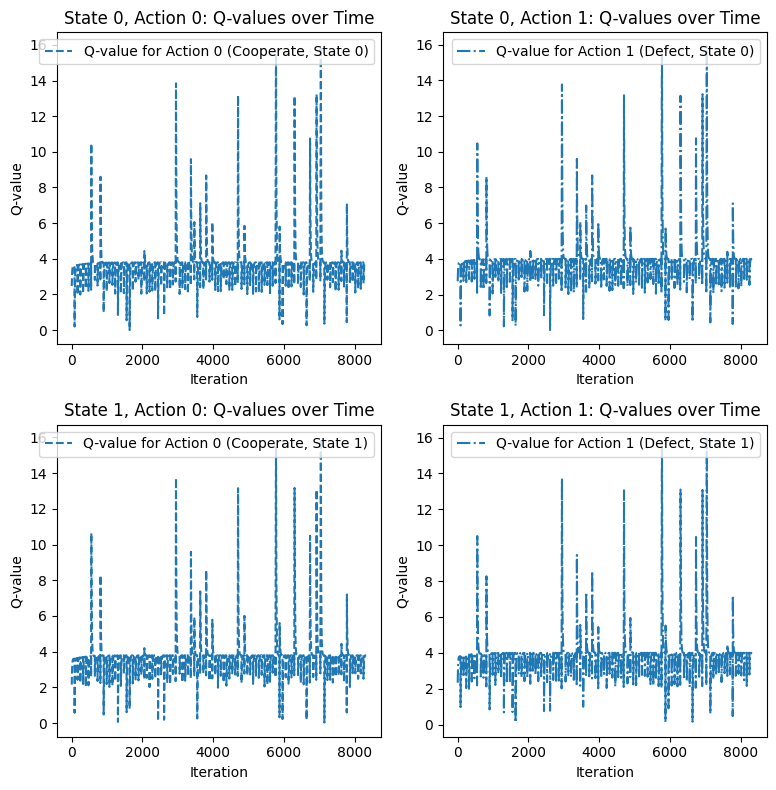

In [12]:
algorithm_edecay(e_initial=0.1, lambda_val=0.1, alpha=0.1, delta=0.95, random_uniform=True, K=500, M=100, e_decay=0.8, error_stop = 'mean', verbose=True)

Final Q-values for Player 1:
[[0.59887038 0.59955403]
 [0.79898895 0.79862067]]
Number of collaborations (Cooperation, Action 0): 4808
Number of defections (Defection, Action 1): 62100
With delta < 0.9, the player is expected to defect more.


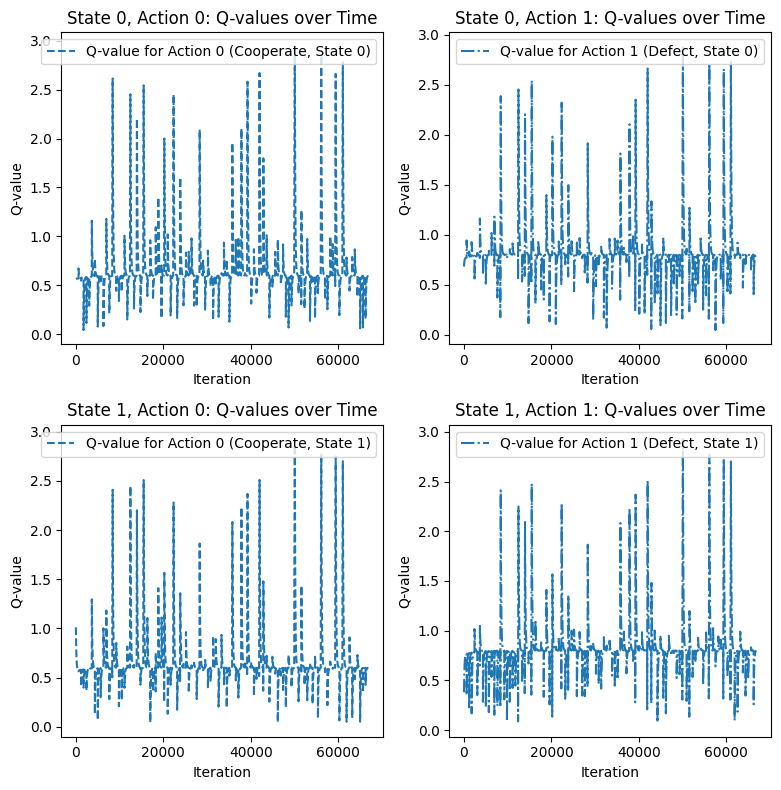

In [14]:
algorithm_edecay(e_initial=0.1, lambda_val=0.1, alpha=0.01, delta=0.75, random_uniform=True, K=500, M=100, e_decay=0.75, error_stop = 'mean',verbose=True)

## Error: Any

In [ ]:
a = [[-0.59688232,0.59676187], [-0.79762052,0.7978569 ]]

In [10]:
np.abs(a)

array([[0.59688232, 0.59676187],
       [0.79762052, 0.7978569 ]])

Final Q-values for Player 1:
[[1.80087231 1.80086382]
 [2.00081781 2.00081537]]
Number of collaborations (Cooperation, Action 0): 459
Number of defections (Defection, Action 1): 7191
With delta < 0.9, the player is expected to defect more.


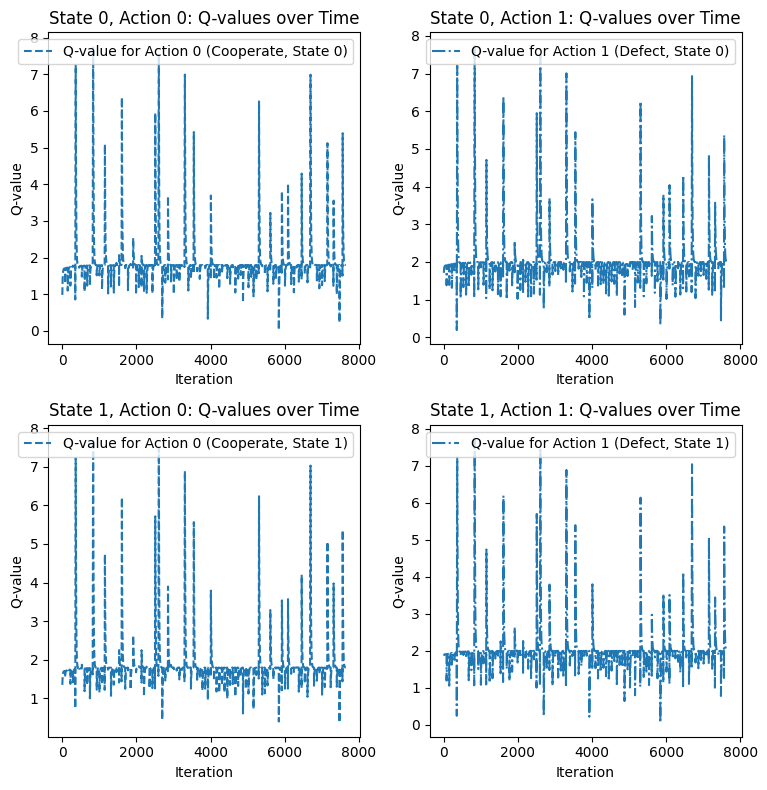

In [11]:
algorithm_edecay(e_initial=0.1, lambda_val=0.1, alpha=0.1, delta=0.9, random_uniform=True, K=500, M=100, e_decay=0.8, error_stop = 'any', verbose=True)


Final Q-values for Player 1:
[[0.59688232 0.59676187]
 [0.79762052 0.7978569 ]]
Number of collaborations (Cooperation, Action 0): 188
Number of defections (Defection, Action 1): 6420
With delta < 0.9, the player is expected to defect more.


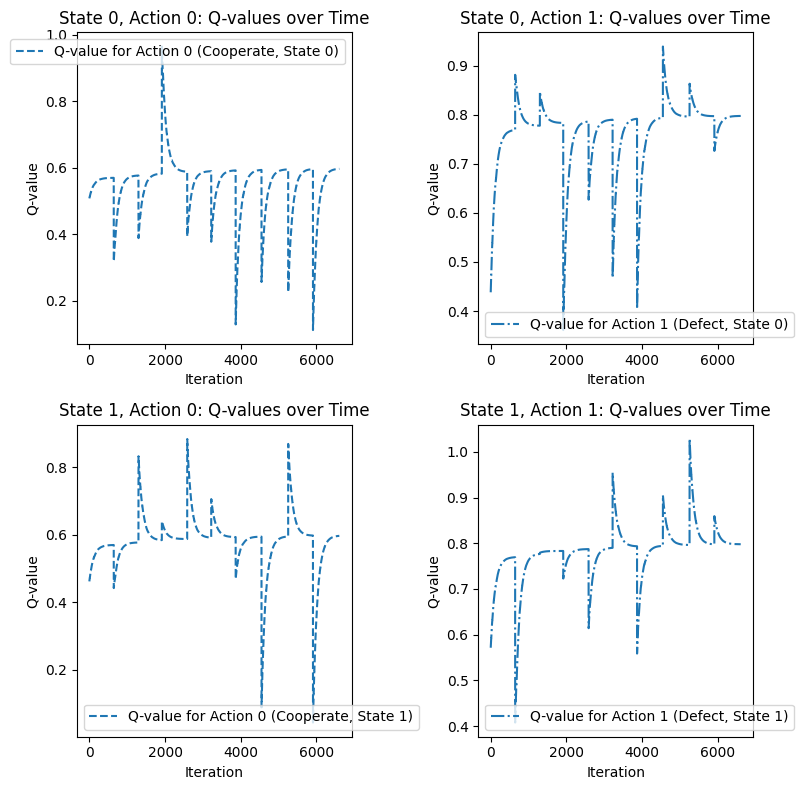

In [41]:
algorithm_edecay(e_initial=0.1, lambda_val=0.1, alpha=0.01, delta=0.75, random_uniform=True, K=1000, M=10, e_decay=0.75, error_stop = 'any', verbose=True)


## Test Library

In [ ]:
"""""
Tit For Tat
delta: 0.99-> Number of collaborations: 57 
delta: 0.95-> Number of collaborations: 46
delta: 0.9-> Number of collaborations: 50



delta: 0.6-> Number of collaborations: 32
delta: 0.1-> Number of collaborations: 30


"""""

In [ ]:
"""""
GrimTrigger:
delta: 0.1 --> Number of collaborations: 63
delta: 0.3 --> Number of collaborations: 25
delta: 0.5 --> Number of collaborations: 52
delta:0.75 --> Number of collaborations: 21
delta:0.9 --> Number of collaborations: 107
delta:0.95 --> Number of collaborations: 47
delta:0.99 --> Number of collaborations: 52
"""""

In [1]:
from SingleAgent import *

Final Q-values for Player 1:
[[1.79999162 1.79999448]
 [1.99998978 1.99999142]]
Final Q-values for Player 1 tell us that the player is Defecting
Number of collaborations: 284, Number of defections: 5400
Expected behavior: collaborate more


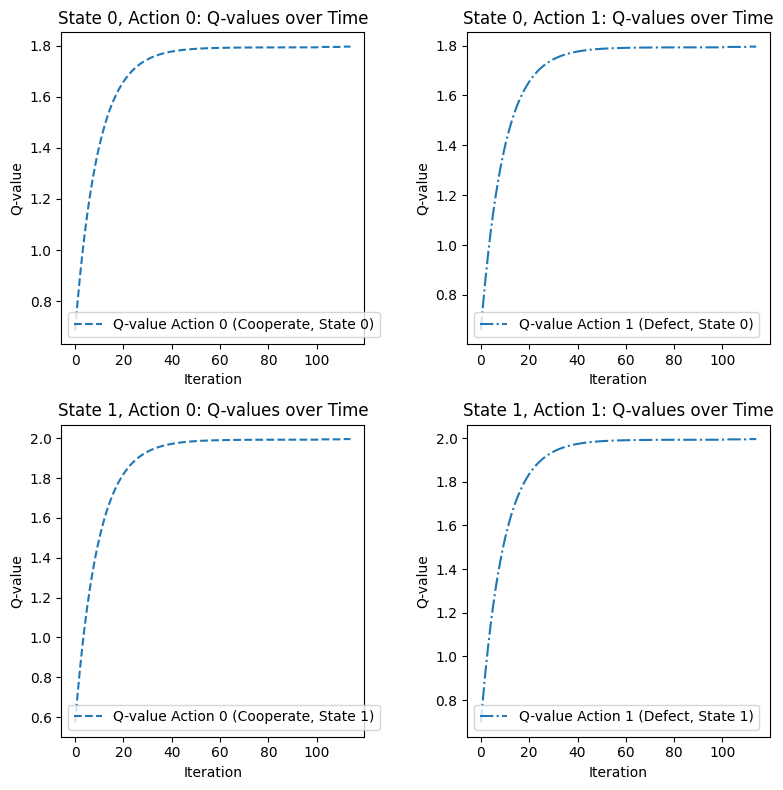

In [13]:
# Initialize strategy and solver
strategy = GrimTrigger()  # Or use TitForTat()
solver = PrisonersDilemmaSolver(strategy, e_initial=0.1, lambda_val=0, alpha=0.1, delta=0.9, K=1000, M=50, e_decay=0.75, error_stop='mean', verbose=True, plotting=True)
cooperations, defections, q_h, q_p_m = solver.run()

Final Q-values for Player 1:
[[0.19000556 0.19000856]
 [0.39000498 0.39000711]]
Final Q-values for Player 1 tell us that the player is Defecting
Number of collaborations: 390, Number of defections: 882
Expected behavior: defect more


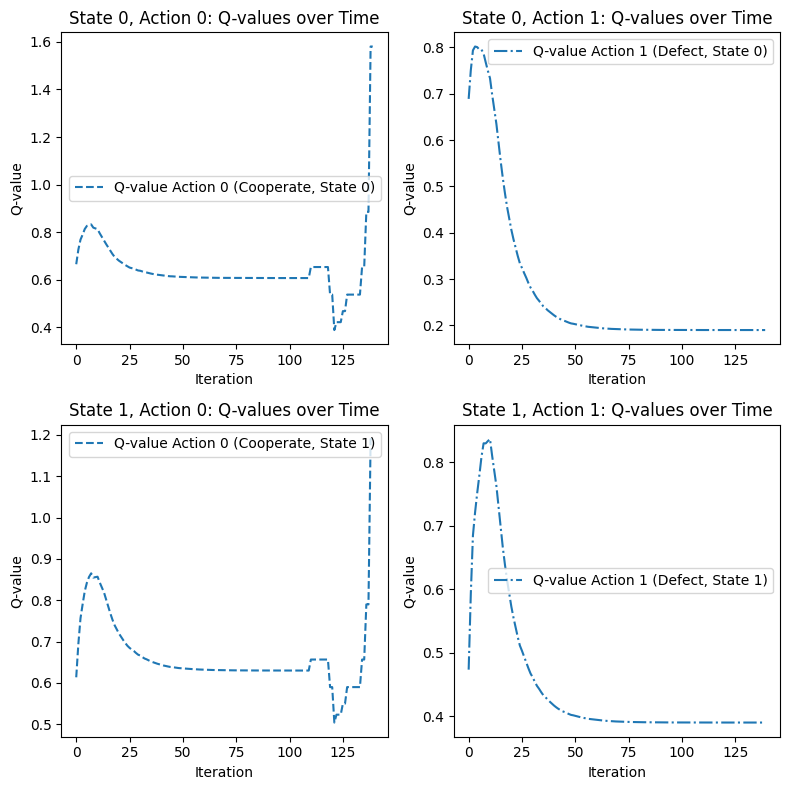

Cooperations: 390, Defections: 882


In [6]:
# Initialize the solver with GrimTrigger_QValues
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=0.1,
    lambda_val=0.1,
    alpha=0.1,
    delta=0.5,
    K=500,
    M=10,
    e_decay=1,
    verbose=True
)

# Run the solver
cooperations, defections, q1_history, mean_q_values = solver.run()

# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=0.1, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


Number of collaborations: 58, Number of defections: 1365
Expected behavior: defect more
Number of collaborations: 149, Number of defections: 1293
Expected behavior: defect more
Number of collaborations: 143, Number of defections: 1344
Expected behavior: defect more
Number of collaborations: 127, Number of defections: 1310
Expected behavior: defect more
Number of collaborations: 132, Number of defections: 1324
Expected behavior: defect more
Number of collaborations: 78, Number of defections: 1345
Expected behavior: defect more
Number of collaborations: 67, Number of defections: 1338
Expected behavior: defect more
Number of collaborations: 59, Number of defections: 1376
Expected behavior: defect more
Number of collaborations: 92, Number of defections: 1277
Expected behavior: defect more
Number of collaborations: 27, Number of defections: 1391
Expected behavior: defect more
Mean cooperations: 93.2
Mean defections: 1336.3


In [ ]:
"""""
GrimTrigger:
delta 0.95 = Mean cooperations: 95.3
delta 0.75 = Mean cooperations: 126.5
delta 0.5 = Mean cooperations: 97.8
delta 0.1 = Mean cooperations: 93.2

"""""
